<a href="https://colab.research.google.com/github/baruch-abh/Metodos-Numericos/blob/main/BHAB_DIFERENCIAS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Fórmula de las diferencias divididas de Newton**

Para obtener los coeficientes de las diferencias divididas del polinomio de interpolación $P$ en los $n+1$ números distintos $x_0,x_1,\ldots,x_n$, para la función $f$:

ENTRADA: los números $x_0,x_1,\ldots,x_n$; valores $f(x_0),f(x_1),\ldots,f(x_n)$ conforme

$F_{0,0},\; F_{1,0},\; \ldots,\; F_{n,0}$
SALIDA:   los números $F_{0,0},F_{1,1},\ldots,F_{n,n}$ , donde

$P_n(x)=F_{0,0}
+\sum_{i=1}^{n}
F_{i,i}
\prod_{j=0}^{i-1}(x-x_j),
\qquad
(F_{i,i}=f[x_0,x_1,\ldots,x_i]).$

**Paso 1**


Para $i=1,2,\ldots,n$

Para $j=1,2,\ldots,i$

$F_{i,j}=\frac{F_{i,j-1}-F_{i-1,j-1}}{x_i-x_{i-j}},
\qquad
(F_{i,j}=f[x_{i-j},\ldots,x_i]).$

**Paso 2**

SALIDA:

$(F_{0,0},F_{1,1},\ldots,F_{n,n})$
PARE.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# DATOS DEL EJEMPLO 1


x = np.array([1.0, 1.3, 1.6, 1.9, 2.2])

y = np.array([
    0.7651977,
    0.6200860,
    0.4554022,
    0.2818186,
    0.1103623
])

n = len(x)



F = np.zeros((n, n))

# Primera columna
F[:, 0] = y

# Calcular diferencias divididas
for i in range(1, n):
    for j in range(1, i + 1):
        F[i, j] = (F[i, j - 1] - F[i - 1, j - 1]) / (x[i] - x[i - j])

# TABLA DE DIFERENCIAS


columnas = [
    "f[x]",
    "f[xi-1,xi]",
    "f[xi-2,xi-1,xi]",
    "f[xi-3,...,xi]",
    "f[xi-4,...,xi]"
]

tabla = pd.DataFrame(F, columns=columnas)
tabla.insert(0, "xi", x)

print("\nTABLA DE DIFERENCIAS DIVIDIDAS\n")
print(tabla.round(7))


# COEFICIENTES DE NEWTON


coef = np.diag(F)

print("\nCOEFICIENTES DEL POLINOMIO DE NEWTON\n")

for i, c in enumerate(coef):
    print(f"F[{i},{i}] = {c:.7f}")

# FUNCION POLINOMIO NEWTON

def newton(x_eval, x_datos, coef):
    n = len(coef)

    resultado = coef[0]

    for i in range(1, n):
        termino = coef[i]

        for j in range(i):
            termino *= (x_eval - x_datos[j])

        resultado += termino

    return resultado


# MOSTRAR POLINOMIO

print("\nPOLINOMIO DE NEWTON\n")

print(
    "P(x) = "
    f"{coef[0]:.7f}"
    f" + ({coef[1]:.7f})(x-1.0)"
    f" + ({coef[2]:.7f})(x-1.0)(x-1.3)"
    f" + ({coef[3]:.7f})(x-1.0)(x-1.3)(x-1.6)"
    f" + ({coef[4]:.7f})(x-1.0)(x-1.3)(x-1.6)(x-1.9)"
)


# EVALUACIÓN


xp = np.linspace(1.0, 2.2, 500)
yp = [newton(valor, x, coef) for valor in xp]




TABLA DE DIFERENCIAS DIVIDIDAS

    xi      f[x]  f[xi-1,xi]  f[xi-2,xi-1,xi]  f[xi-3,...,xi]  f[xi-4,...,xi]
0  1.0  0.765198    0.000000         0.000000        0.000000        0.000000
1  1.3  0.620086   -0.483706         0.000000        0.000000        0.000000
2  1.6  0.455402   -0.548946        -0.108734        0.000000        0.000000
3  1.9  0.281819   -0.578612        -0.049443        0.065878        0.000000
4  2.2  0.110362   -0.571521         0.011818        0.068069        0.001825

COEFICIENTES DEL POLINOMIO DE NEWTON

F[0,0] = 0.7651977
F[1,1] = -0.4837057
F[2,2] = -0.1087339
F[3,3] = 0.0658784
F[4,4] = 0.0018251

POLINOMIO DE NEWTON

P(x) = 0.7651977 + (-0.4837057)(x-1.0) + (-0.1087339)(x-1.0)(x-1.3) + (0.0658784)(x-1.0)(x-1.3)(x-1.6) + (0.0018251)(x-1.0)(x-1.3)(x-1.6)(x-1.9)


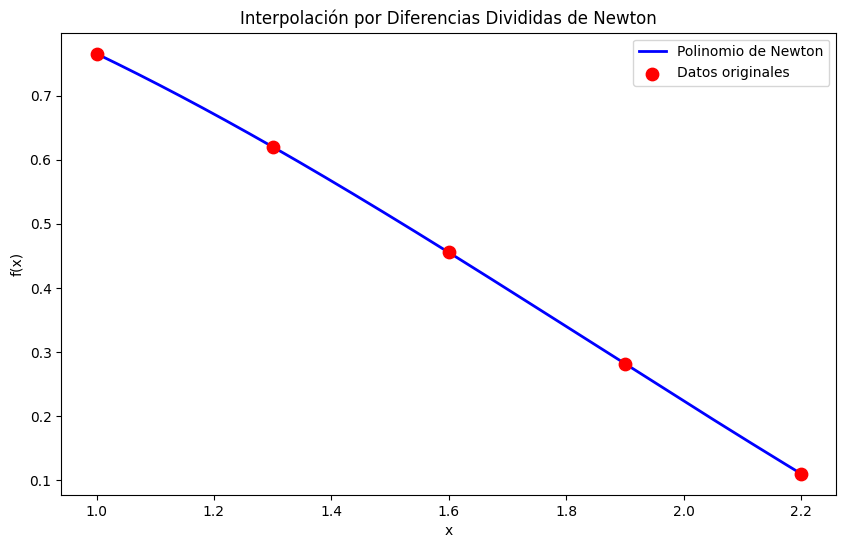

In [4]:

# GRAFICA


plt.figure(figsize=(10,6))

plt.plot(
    xp,
    yp,
    color='blue',
    linewidth=2,
    label='Polinomio de Newton'
)

plt.scatter(
    x,
    y,
    color='red',
    s=80,
    zorder=5,
    label='Datos originales'
)

plt.title("Interpolación por Diferencias Divididas de Newton")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()

plt.show()